In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

In [4]:
df = pd.read_csv("london_weather_data_1979_to_2023.csv")

In [5]:
df

,DATE,TX,Q_TX,TN,Q_TN,TG,Q_TG,SS,Q_SS,SD,...,RR,Q_RR,QQ,Q_QQ,PP,Q_PP,HU,Q_HU,CC,Q_CC
0,19790101,23.0,0,-75.0,0,-41.0,0,70.0,0,9.0,...,4.0,0,52.0,0,10190.0,0,83.0,0,2.0,0
1,19790102,16.0,0,-75.0,0,-26.0,0,17.0,0,8.0,...,0.0,0,27.0,0,10253.0,0,76.0,0,6.0,0
2,19790103,13.0,0,-72.0,0,-28.0,0,0.0,0,4.0,...,0.0,0,13.0,0,10205.0,0,86.0,0,5.0,0
3,19790104,-3.0,0,-65.0,0,-26.0,0,0.0,0,2.0,...,0.0,0,13.0,0,10084.0,0,68.0,0,8.0,0
4,19790105,56.0,0,-14.0,0,-8.0,0,20.0,0,1.0,...,0.0,0,29.0,0,10225.0,0,73.0,0,6.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16431,20231227,126.0,0,55.0,0,89.0,0,0.0,0,0.0,...,46.0,0,12.0,0,10067.0,0,89.0,0,8.0,0
16432,20231228,119.0,0,97.0,0,112.0,0,2.0,0,0.0,...,48.0,0,15.0,0,10051.0,0,81.0,0,7.0,0
16433,20231229,122.0,0,92.0,0,106.0,0,7.0,0,0.0,...,0.0,0,20.0,0,10071.0,0,78.0,0,6.0,0
16434,20231230,107.0,0,56.0,0,89.0,0,0.0,0,0.0,...,56.0,0,12.0,0,10046.0,0,87.0,0,7.0,0


In [6]:
print("Ukuran data")
print("Baris :", df.shape[0])
print("Kolom :", df.shape[1])

Ukuran data
Baris : 16436
Kolom : 21


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16436 entries, 0 to 16435
Data columns (total 21 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   DATE    16436 non-null  int64  
 1   TX      16436 non-null  float64
 2   Q_TX    16436 non-null  int64  
 3   TN      16436 non-null  float64
 4   Q_TN    16436 non-null  int64  
 5   TG      16407 non-null  float64
 6   Q_TG    16436 non-null  int64  
 7   SS      16436 non-null  float64
 8   Q_SS    16436 non-null  int64  
 9   SD      15361 non-null  float64
 10  Q_SD    16436 non-null  int64  
 11  RR      16436 non-null  float64
 12  Q_RR    16436 non-null  int64  
 13  QQ      16411 non-null  float64
 14  Q_QQ    16436 non-null  int64  
 15  PP      16432 non-null  float64
 16  Q_PP    16436 non-null  int64  
 17  HU      16379 non-null  float64
 18  Q_HU    16436 non-null  int64  
 19  CC      16418 non-null  float64
 20  Q_CC    16436 non-null  int64  
dtypes: float64(10), int64(11)
memory usage: 2.6 MB

In [8]:
df.head()

,DATE,TX,Q_TX,TN,Q_TN,TG,Q_TG,SS,Q_SS,SD,...,RR,Q_RR,QQ,Q_QQ,PP,Q_PP,HU,Q_HU,CC,Q_CC
0,19790101,23.0,0,-75.0,0,-41.0,0,70.0,0,9.0,...,4.0,0,52.0,0,10190.0,0,83.0,0,2.0,0
1,19790102,16.0,0,-75.0,0,-26.0,0,17.0,0,8.0,...,0.0,0,27.0,0,10253.0,0,76.0,0,6.0,0
2,19790103,13.0,0,-72.0,0,-28.0,0,0.0,0,4.0,...,0.0,0,13.0,0,10205.0,0,86.0,0,5.0,0
3,19790104,-3.0,0,-65.0,0,-26.0,0,0.0,0,2.0,...,0.0,0,13.0,0,10084.0,0,68.0,0,8.0,0
4,19790105,56.0,0,-14.0,0,-8.0,0,20.0,0,1.0,...,0.0,0,29.0,0,10225.0,0,73.0,0,6.0,0


In [9]:
df.describe(include="all")

,DATE,TX,Q_TX,TN,Q_TN,TG,Q_TG,SS,Q_SS,SD,...,RR,Q_RR,QQ,Q_QQ,PP,Q_PP,HU,Q_HU,CC,Q_CC
count,1.643600e+04,16436.000000,16436.000000,16436.000000,16436.000000,16407.000000,16436.000000,16436.000000,16436.0,15361.000000,...,16436.000000,16436.0,16411.00000,16436.000000,16432.000000,16436.00000,16379.000000,16436.000000,16418.000000,16436.000000
mean,2.001066e+07,154.686846,0.068082,76.016427,0.015454,115.373316,0.083962,43.153626,0.0,0.034633,...,16.791738,0.0,119.52020,0.017036,10153.889423,0.00219,76.283717,0.031212,5.256426,0.009978
std,1.298742e+05,65.741246,0.251895,53.392049,0.123353,57.457444,0.451623,39.992648,0.0,0.519639,...,37.614507,0.0,89.26958,0.355343,105.196268,0.14039,10.520699,0.529104,2.091593,0.297885
min,1.979010e+07,-62.000000,0.000000,-118.000000,0.000000,-76.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.0,0.00000,0.000000,9596.000000,0.00000,33.000000,0.000000,0.000000,0.000000
25%,1.990040e+07,106.000000,0.000000,36.000000,0.000000,72.000000,0.000000,4.000000,0.0,0.000000,...,0.000000,0.0,42.00000,0.000000,10091.000000,0.00000,69.000000,0.000000,4.000000,0.000000
50%,2.001070e+07,151.000000,0.000000,78.000000,0.000000,114.000000,0.000000,35.000000,0.0,0.000000,...,0.000000,0.0,96.00000,0.000000,10162.000000,0.00000,77.000000,0.000000,6.000000,0.000000
75%,2.012095e+07,204.000000,0.000000,118.000000,0.000000,161.000000,0.000000,71.000000,0.0,0.000000,...,16.000000,0.0,187.00000,0.000000,10225.000000,0.00000,84.000000,0.000000,7.000000,0.000000
max,2.023123e+07,402.000000,1.000000,223.000000,1.000000,309.000000,9.000000,157.000000,0.0,22.000000,...,618.000000,0.0,402.00000,9.000000,10477.000000,9.00000,100.000000,9.000000,9.000000,9.000000


In [10]:
print("Jumlah baris duplikat:", df.duplicated().sum())

Jumlah baris duplikat: 0


In [11]:
missing_values = df.isnull().sum()

missing_values[missing_values > 0]

TG      29
SD    1075
QQ      25
PP       4
HU      57
CC      18
dtype: int64

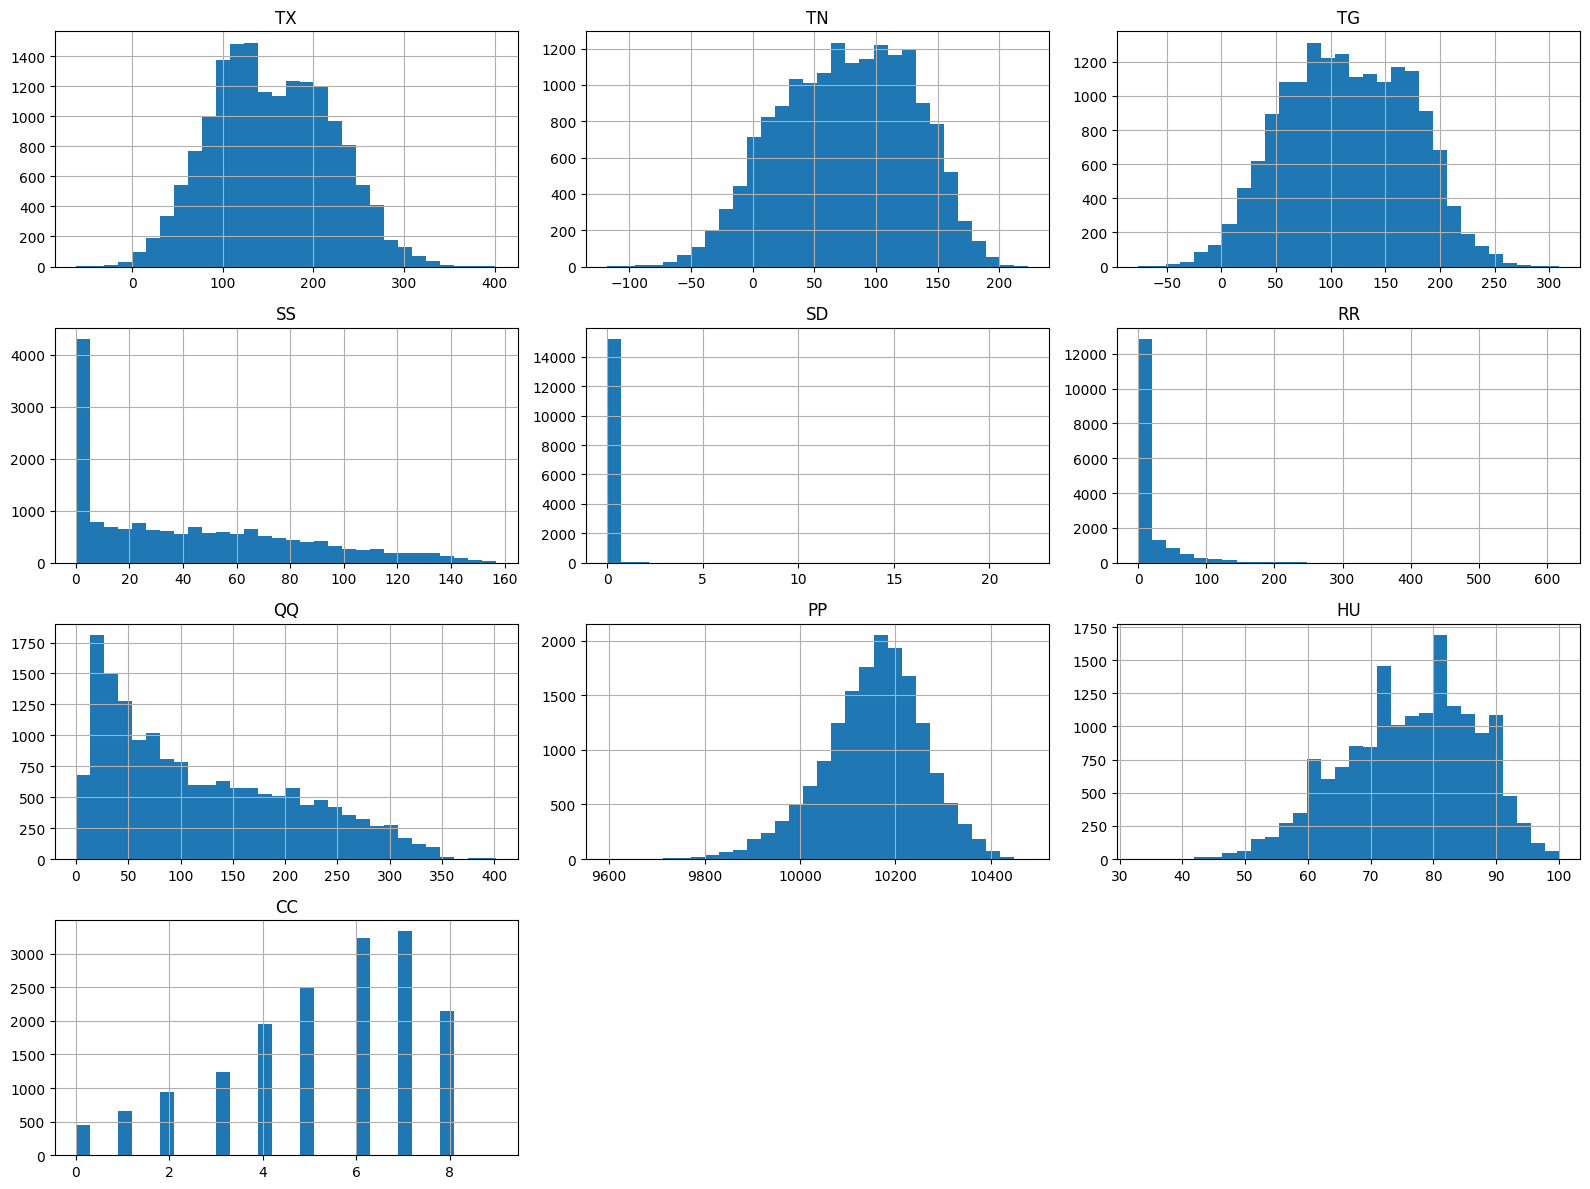

In [12]:
eda_columns = [
    col for col in df.select_dtypes(include="number").columns
    if not col.startswith("Q_") and col != "DATE"
]

df[eda_columns].hist(
    figsize=(16, 12),
    bins=30
)

plt.tight_layout()
plt.show()

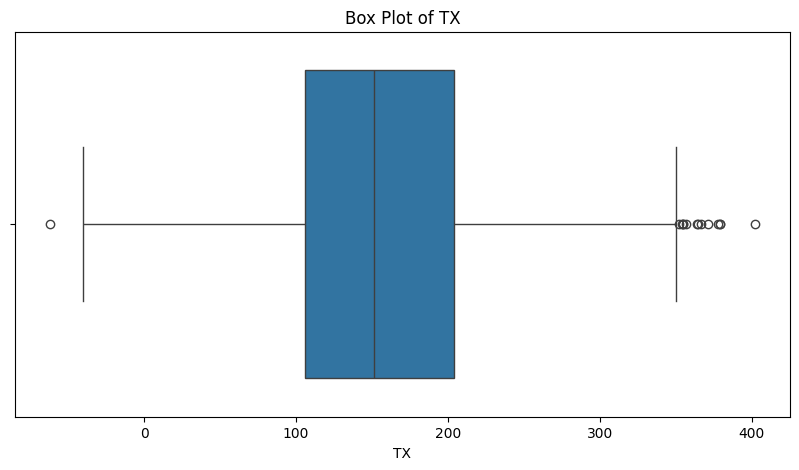

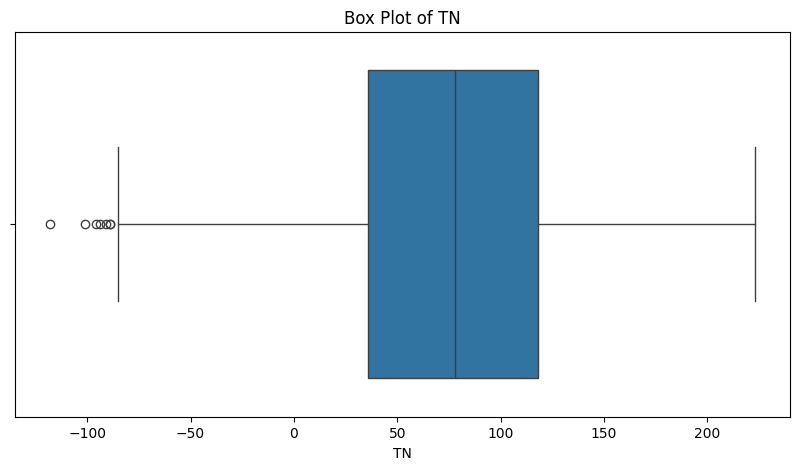

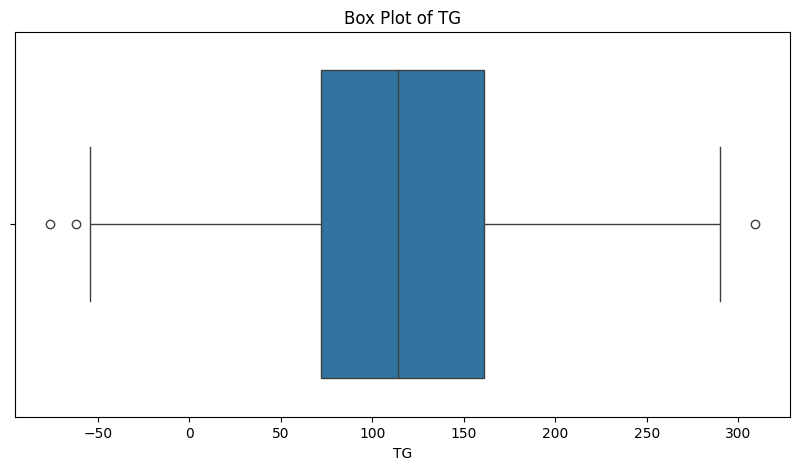

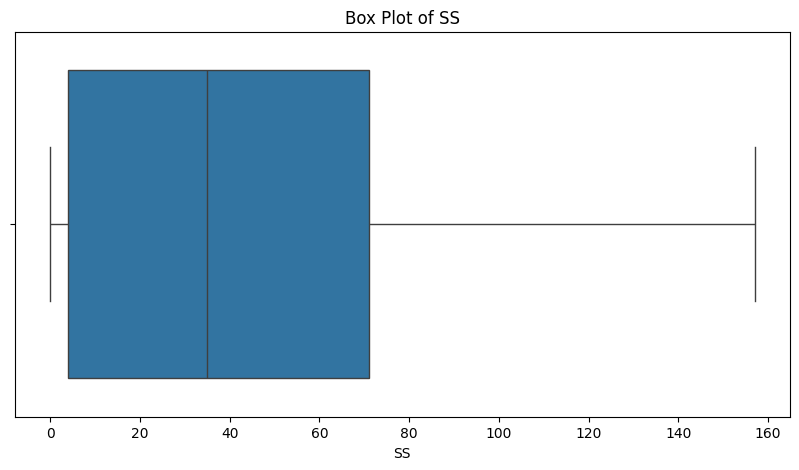

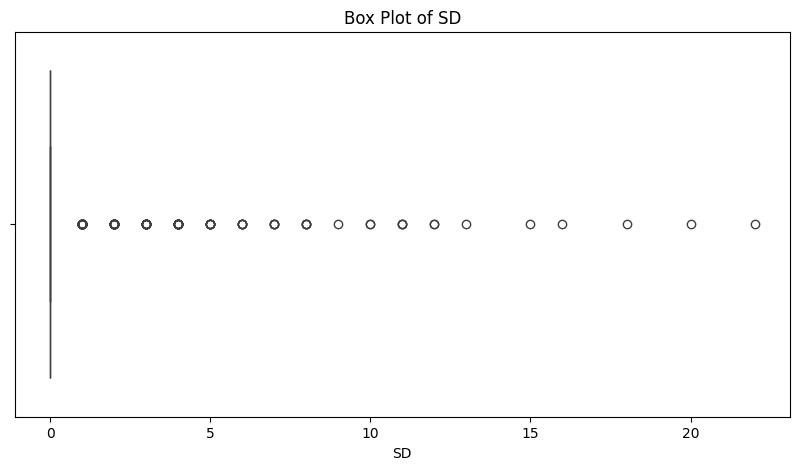

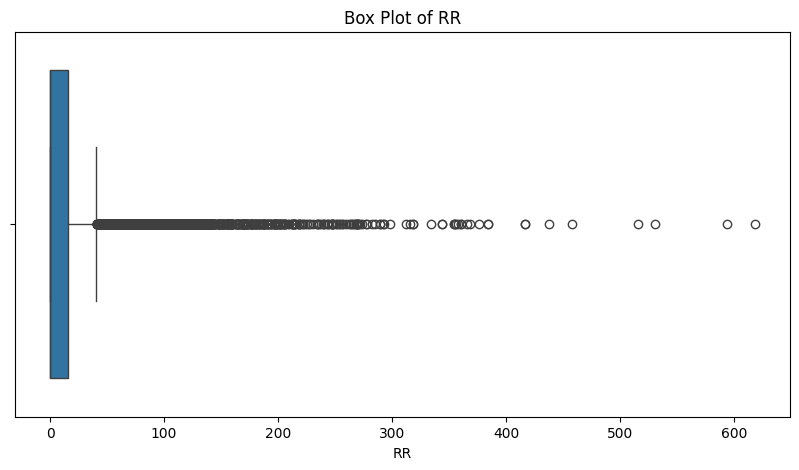

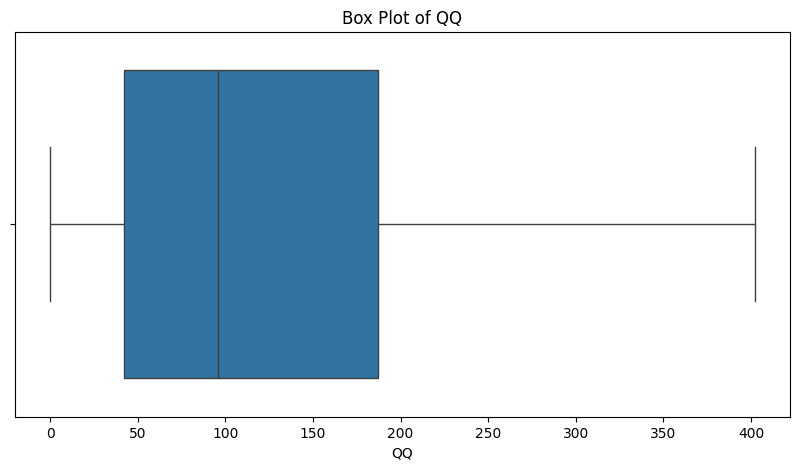

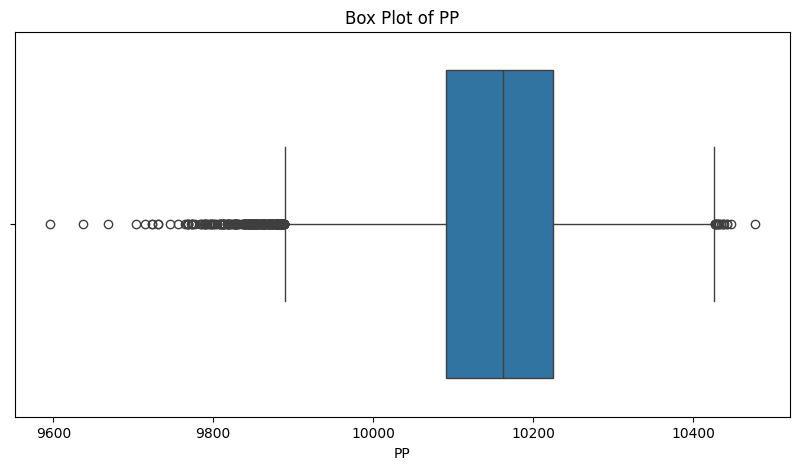

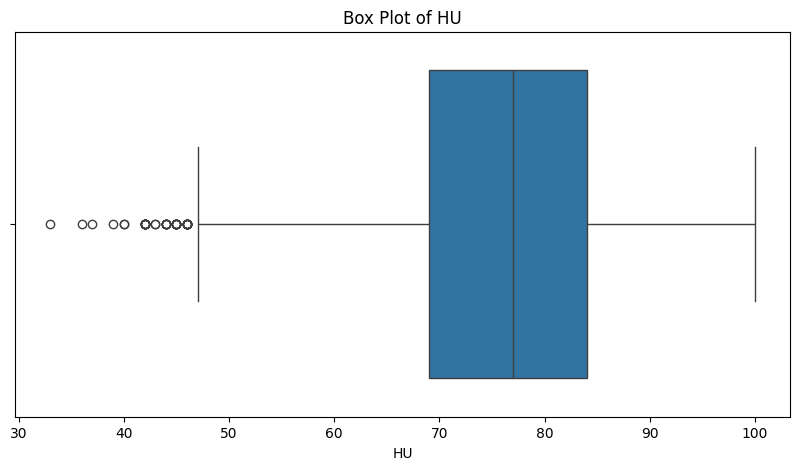

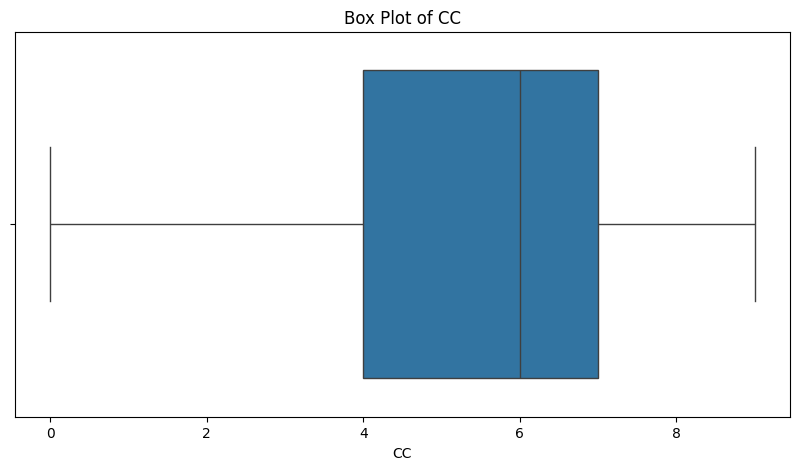

In [13]:
eda_numeric_features = df.select_dtypes(
    include=["number"]
).columns

eda_numeric_features = [
    col for col in eda_numeric_features
    if not col.startswith("Q_") and col != "DATE"
]

for feature in eda_numeric_features:
    plt.figure(figsize=(10, 5))

    sns.boxplot(x=df[feature])

    plt.title(f"Box Plot of {feature}")
    plt.xlabel(feature)

    plt.show()

In [14]:
print("Statistik deskriptif fitur cuaca\n")

print(df[eda_numeric_features].describe().T)

Statistik deskriptif fitur cuaca

      count          mean         std     min      25%      50%      75%  \
TX  16436.0    154.686846   65.741246   -62.0    106.0    151.0    204.0   
TN  16436.0     76.016427   53.392049  -118.0     36.0     78.0    118.0   
TG  16407.0    115.373316   57.457444   -76.0     72.0    114.0    161.0   
SS  16436.0     43.153626   39.992648     0.0      4.0     35.0     71.0   
SD  15361.0      0.034633    0.519639     0.0      0.0      0.0      0.0   
RR  16436.0     16.791738   37.614507     0.0      0.0      0.0     16.0   
QQ  16411.0    119.520200   89.269580     0.0     42.0     96.0    187.0   
PP  16432.0  10153.889423  105.196268  9596.0  10091.0  10162.0  10225.0   
HU  16379.0     76.283717   10.520699    33.0     69.0     77.0     84.0   
CC  16418.0      5.256426    2.091593     0.0      4.0      6.0      7.0   

        max  
TX    402.0  
TN    223.0  
TG    309.0  
SS    157.0  
SD     22.0  
RR    618.0  
QQ    402.0  
PP  10477.0  
HU 

In [15]:
print("Distribusi Target TG")

print(df["TG"].describe())

print("\nJumlah missing values pada TG:")
print(df["TG"].isnull().sum())

Distribusi Target TG
count    16407.000000
mean       115.373316
std         57.457444
min        -76.000000
25%         72.000000
50%        114.000000
75%        161.000000
max        309.000000
Name: TG, dtype: float64

Jumlah missing values pada TG:
29


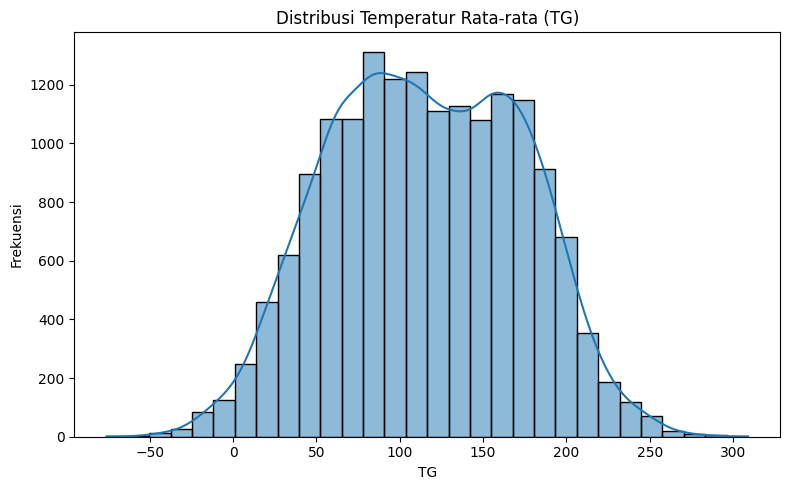

In [16]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="TG",
    bins=30,
    kde=True
)

plt.title("Distribusi Temperatur Rata-rata (TG)")
plt.xlabel("TG")
plt.ylabel("Frekuensi")

plt.tight_layout()
plt.show()

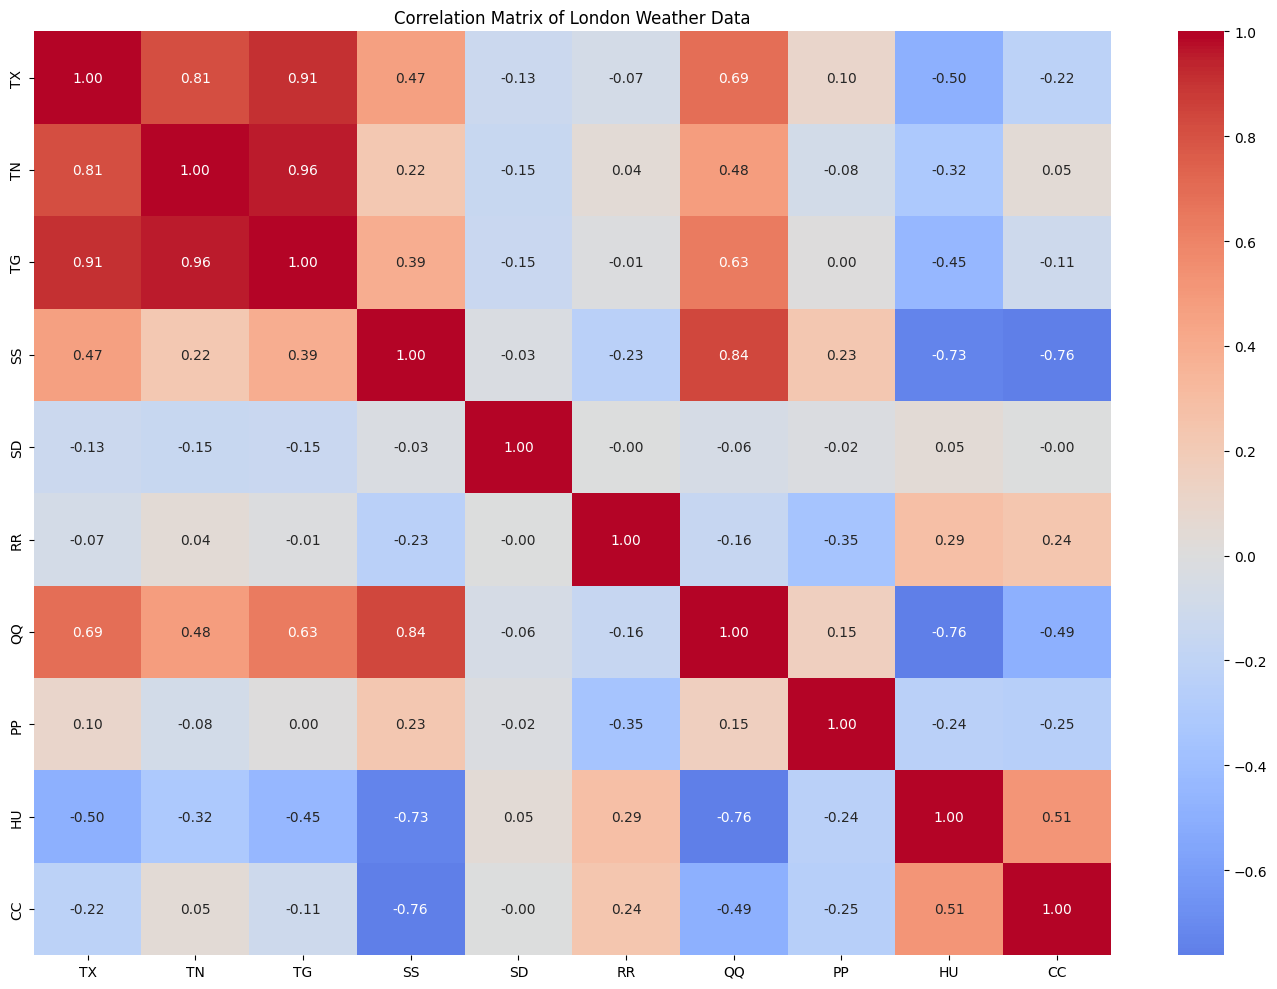

In [29]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    df[eda_numeric_features].corr(),
    cmap="coolwarm",
    annot=True,
    fmt=".2f",
    center=0
)

plt.title("Correlation Matrix of London Weather Data")
plt.tight_layout()
plt.show()

In [30]:
df_model = df.copy()

df_model["DATE"] = pd.to_datetime(
    df_model["DATE"].astype(str),
    format="%Y%m%d",
    errors="coerce"
)

df_model = df_model.dropna(subset=["DATE"])

df_model["YEAR"] = df_model["DATE"].dt.year
df_model["MONTH"] = df_model["DATE"].dt.month
df_model["DAY"] = df_model["DATE"].dt.day
df_model["DAY_OF_YEAR"] = df_model["DATE"].dt.dayofyear

# Menghapus kolom penanda kualitas
quality_columns = [
    col for col in df_model.columns
    if col.startswith("Q_")
]

df_model = df_model.drop(
    columns=quality_columns + ["DATE"]
)

# Memastikan target TG berupa numerik
df_model["TG"] = pd.to_numeric(
    df_model["TG"],
    errors="coerce"
)

# Menghapus baris yang target TG-nya kosong
df_model = df_model.dropna(subset=["TG"])

print("Jumlah data setelah membersihkan TG:", len(df_model))
print("Missing values pada TG:", df_model["TG"].isnull().sum())

Jumlah data setelah membersihkan TG: 16407
Missing values pada TG: 0


In [31]:
X = df_model.drop(columns=["TG"])
y = df_model["TG"]

print("Missing values pada target:", y.isnull().sum())
print("Jumlah data X:", len(X))
print("Jumlah data y:", len(y))

Missing values pada target: 0
Jumlah data X: 16407
Jumlah data y: 16407


In [32]:
split_index = int(len(df_model) * 0.8)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("NaN pada y_train:", y_train.isnull().sum())
print("NaN pada y_test:", y_test.isnull().sum())

NaN pada y_train: 0
NaN pada y_test: 0


In [33]:
numeric_features = [
    "TX",
    "TN",
    "SS",
    "SD",
    "RR",
    "QQ",
    "PP",
    "HU",
    "CC"
]

In [34]:
calendar_features = [
    "YEAR",
    "MONTH",
    "DAY",
    "DAY_OF_YEAR"
]

In [35]:
feature_columns = numeric_features + calendar_features

X_train = X_train[feature_columns]
X_test = X_test[feature_columns]

print("Jumlah fitur:", len(feature_columns))
print("Daftar fitur:", feature_columns)

Jumlah fitur: 13
Daftar fitur: ['TX', 'TN', 'SS', 'SD', 'RR', 'QQ', 'PP', 'HU', 'CC', 'YEAR', 'MONTH', 'DAY', 'DAY_OF_YEAR']


In [36]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [37]:
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, feature_columns)
])

In [38]:
linear_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

print("Linear Regression berhasil dijalankan!")

Linear Regression berhasil dijalankan!


In [39]:
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Training
random_forest_model.fit(X_train, y_train)

# Prediksi
y_pred_rf = random_forest_model.predict(X_test)

In [40]:
hist_gradient_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", HistGradientBoostingRegressor(
        max_iter=100,
        random_state=42
    ))
])

# Training
hist_gradient_model.fit(X_train, y_train)

# Prediksi
y_pred_hgb = hist_gradient_model.predict(X_test)

In [41]:
def evaluasi_model(nama_model, y_test, y_pred):
    mae = mean_absolute_error(y_test, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    r2 = r2_score(y_test, y_pred)

    print("\n" + "=" * 60)
    print(nama_model)
    print("=" * 60)

    print(f"MAE  : {mae:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"R2   : {r2:.4f}")

    return [mae, rmse, r2]

In [42]:
# Evaluasi Linear Regression
hasil_linear = evaluasi_model(
    "Linear Regression",
    y_test,
    y_pred_linear
)

# Evaluasi Random Forest
hasil_rf = evaluasi_model(
    "Random Forest Regressor",
    y_test,
    y_pred_rf
)

# Evaluasi HistGradientBoosting
hasil_hgb = evaluasi_model(
    "HistGradientBoosting Regressor",
    y_test,
    y_pred_hgb
)


Linear Regression
MAE  : 7.3455
RMSE : 9.6017
R2   : 0.9719

Random Forest Regressor
MAE  : 7.0548
RMSE : 9.2169
R2   : 0.9741

HistGradientBoosting Regressor
MAE  : 6.8328
RMSE : 8.8898
R2   : 0.9759


In [43]:
hasil_perbandingan = pd.DataFrame(
    [
        hasil_linear,
        hasil_rf,
        hasil_hgb
    ],
    columns=[
        "MAE",
        "RMSE",
        "R2"
    ],
    index=[
        "Linear Regression",
        "Random Forest Regressor",
        "HistGradientBoosting Regressor"
    ]
)

print("\n" + "=" * 60)
print("PERBANDINGAN PERFORMA MODEL")
print("=" * 60)

display(hasil_perbandingan.round(4))


PERBANDINGAN PERFORMA MODEL


,MAE,RMSE,R2
Linear Regression,7.3455,9.6017,0.9719
Random Forest Regressor,7.0548,9.2169,0.9741
HistGradientBoosting Regressor,6.8328,8.8898,0.9759


In [44]:
print("\n" + "=" * 60)
print("PERINGKAT MODEL BERDASARKAN MAE")
print("=" * 60)

display(
    hasil_perbandingan
    .sort_values(
        by="MAE",
        ascending=True
    )
    .round(4)
)


PERINGKAT MODEL BERDASARKAN MAE


,MAE,RMSE,R2
HistGradientBoosting Regressor,6.8328,8.8898,0.9759
Random Forest Regressor,7.0548,9.2169,0.9741
Linear Regression,7.3455,9.6017,0.9719


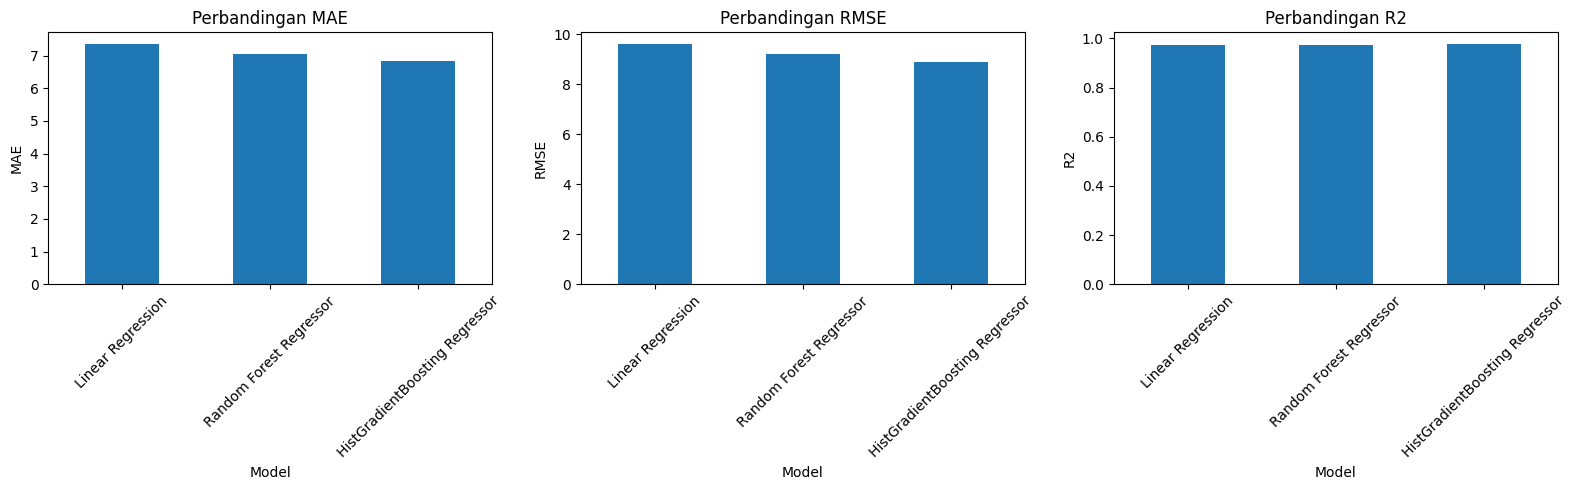

In [45]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)

metrics = ["MAE", "RMSE", "R2"]

for ax, metric in zip(axes, metrics):
    hasil_perbandingan[metric].plot(
        kind="bar",
        ax=ax
    )

    ax.set_title(f"Perbandingan {metric}")
    ax.set_xlabel("Model")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

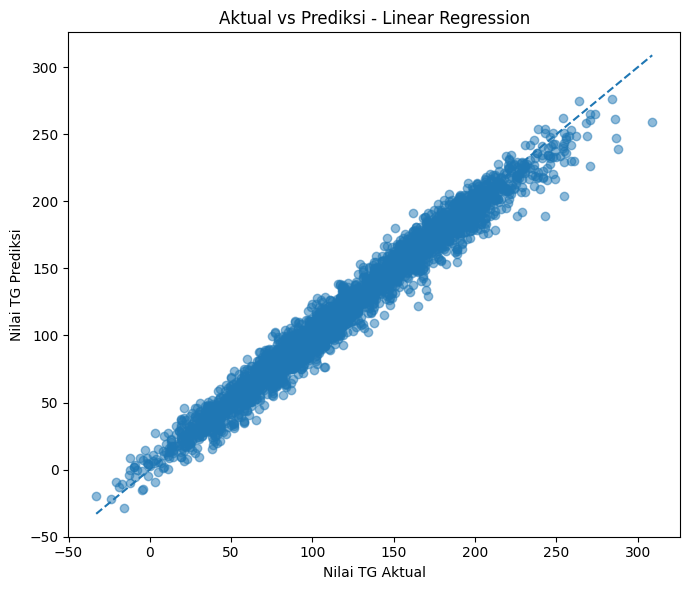

In [46]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred_linear,
    alpha=0.5
)

nilai_min = min(y_test.min(), y_pred_linear.min())
nilai_max = max(y_test.max(), y_pred_linear.max())

plt.plot(
    [nilai_min, nilai_max],
    [nilai_min, nilai_max],
    linestyle="--"
)

plt.title("Aktual vs Prediksi - Linear Regression")
plt.xlabel("Nilai TG Aktual")
plt.ylabel("Nilai TG Prediksi")

plt.tight_layout()
plt.show()

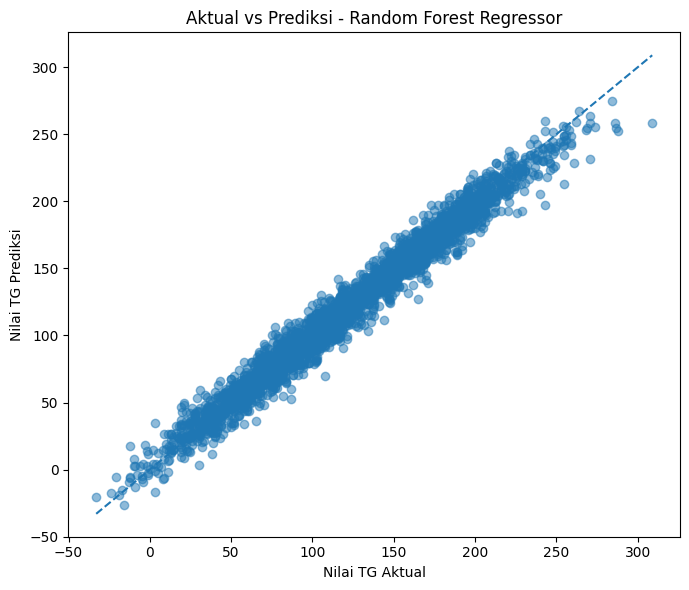

In [47]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred_rf,
    alpha=0.5
)

nilai_min = min(y_test.min(), y_pred_rf.min())
nilai_max = max(y_test.max(), y_pred_rf.max())

plt.plot(
    [nilai_min, nilai_max],
    [nilai_min, nilai_max],
    linestyle="--"
)

plt.title("Aktual vs Prediksi - Random Forest Regressor")
plt.xlabel("Nilai TG Aktual")
plt.ylabel("Nilai TG Prediksi")

plt.tight_layout()
plt.show()

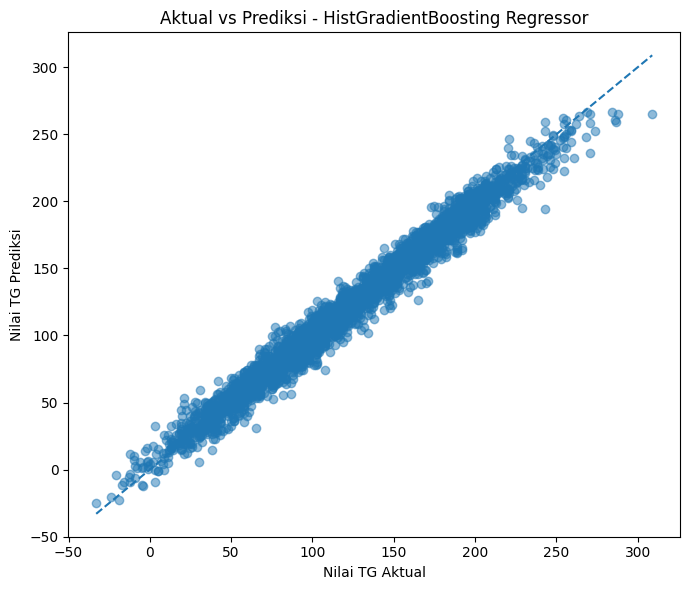

In [48]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred_hgb,
    alpha=0.5
)

nilai_min = min(y_test.min(), y_pred_hgb.min())
nilai_max = max(y_test.max(), y_pred_hgb.max())

plt.plot(
    [nilai_min, nilai_max],
    [nilai_min, nilai_max],
    linestyle="--"
)

plt.title(
    "Aktual vs Prediksi - HistGradientBoosting Regressor"
)

plt.xlabel("Nilai TG Aktual")
plt.ylabel("Nilai TG Prediksi")

plt.tight_layout()
plt.show()

In [49]:
model_terbaik = hasil_perbandingan["MAE"].idxmin()

nilai_mae_terbaik = hasil_perbandingan.loc[
    model_terbaik,
    "MAE"
]

print("=" * 60)
print("MODEL TERBAIK")
print("=" * 60)

print("Model :", model_terbaik)
print(f"MAE   : {nilai_mae_terbaik:.4f}")

MODEL TERBAIK
Model : HistGradientBoosting Regressor
MAE   : 6.8328


In [50]:
model_dict = {
    "Linear Regression": linear_model,
    "Random Forest Regressor": random_forest_model,
    "HistGradientBoosting Regressor": hist_gradient_model
}

model_final = model_dict[model_terbaik]

joblib.dump(
    model_final,
    "london_weather_tg_model.pkl"
)

print("Model terbaik berhasil disimpan.")
print("Nama model:", model_terbaik)
print("File: london_weather_tg_model.pkl")

Model terbaik berhasil disimpan.
Nama model: HistGradientBoosting Regressor
File: london_weather_tg_model.pkl


In [51]:
print("Eksperimen prediksi temperatur TG selesai.")
print("Model terbaik berdasarkan MAE:", model_terbaik)
print("Nilai MAE:", round(nilai_mae_terbaik, 4))

Eksperimen prediksi temperatur TG selesai.
Model terbaik berdasarkan MAE: HistGradientBoosting Regressor
Nilai MAE: 6.8328
